In [1]:
LANG = "de"

# J-Space-Readouts unter Gewichtsquantisierung — Walkthrough

**Frage:** Bleibt das Global-Workspace-Signal, das Anthropics Jacobian Lens aus den Zwischenschichten
eines Sprachmodells liest, unter Quantisierung erhalten?

Dieses Notebook geht Methode und Ergebnisse Schritt für Schritt durch. Es rechnet auf den gespeicherten
Aktivierungen (`results/activations/`) und Ergebnistabellen (`results/tables/`); dahinter steht die
Pipeline `python -m jspace_quant capture | analyze | plot` (siehe `docs/de/03-setup.md`). Ausführlich:
`docs/de/02-methodik.md`, `docs/de/05-ergebnisse.md`.

In [2]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from jspace_quant import analysis, capture, config, readout

pd.set_option("display.precision", 3)
T, F = config.TABLES_DIR, config.FIGURES_DIR / LANG
summary = json.loads((T / "summary.json").read_text())
band = tuple(summary["workspace_band"])

## 1. Modell und Quantisierungen

Spark-X2.6-4B (36 Schichten, Residual-Breite 2560, hybride Sliding-Window-/Full-Attention). Wir verwenden
nur **flache** Quants — jeder Gewichtstensor hat denselben Typ —, damit die Bitbreite die einzige
Variable ist.

- **Hauptstudie:** BF16 (Referenz) → Q8_0 → Q4_0
- **Erweiterung:** Bitbreiten-Leiter in zwei Familien (Legacy: Q5_0; K-Quants: Q6_K … Q2_K) und
  Komponenten-Ablation (nur Attention / MLP / Embedding in Q4_0)

Bits pro Gewicht sind aus den GGUF-Dateien gemessen:

In [3]:
pd.read_csv(T / "models.csv")[["model", "family", "bits_per_weight", "tensor_types"]]

,model,family,bits_per_weight,tensor_types
0,bf16,ref,16.001,"{""BF16"": 217}"
1,q8_0,legacy,8.501,"{""Q8_0"": 217}"
2,q5_0,legacy,5.501,"{""Q5_0"": 217}"
3,q4_0,legacy,4.501,"{""Q4_0"": 217}"
4,q6_k,kquant,6.564,"{""Q6_K"": 217}"
5,q5_k,kquant,5.501,"{""Q5_K"": 217}"
6,q4_k,kquant,4.501,"{""Q4_K"": 217}"
7,q3_k,kquant,3.439,"{""Q3_K"": 217}"
8,q2_k,kquant,2.626,"{""Q2_K"": 217}"
9,q4_0-attn,ablation,13.357,"{""BF16"": 109, ""Q4_0"": 108}"


## 2. Was die Lens tut

Für eine Schicht `l` und eine Position nimmt man den Residual-Stream-Vektor `h_l` und liest ihn aus:

```
logits = Unembed( RMSNorm( A_l · h_l + b_l ) )
```

`A_l` bildet den Raum von Schicht `l` in den Raum der letzten Schicht ab. Mit `A_l = I` ist das der
klassische **Logit Lens**. Das Paper definiert `A_l` als gemittelte Jacobi-Matrix `E[∂h_final/∂h_l]`.
llama.cpp hat kein Autograd, deshalb fitten wir `A_l, b_l` per **Ridge-Regression** von `h_35` auf `h_l`
über 1000 WikiText-Absätze (nur Forward-Pässe — ein korrelatives Surrogat aus der Tuned-Lens-Familie).

**Live-Beispiel** auf den gespeicherten Aktivierungen: der französische Prompt „Après la nuit vient le“
(„nach der Nacht kommt der“) — Antwort „jour“. Im Text steht das französische „nuit“; die Frage ist, ob
das Modell intern das *englische* Konzept „night“ bildet und ab welcher Schicht es lesbar wird.

In [4]:
acts, meta = capture.load("bf16", "evals")
i = next(k for k, it in enumerate(meta) if it["name"] == "fr-time-after-night")
item = meta[i]
print(item["prompt"].split("assistant\n")[-1], "→ target:", item["target"])
night = next(c for c in item["intermediates"] if c["word"] == "night")["token_ids"]

rows = []
for arm_name in ["bf16|identity", "bf16|bf16-A"]:
    arm = config.ARMS_BY_NAME[arm_name]
    for layer in range(0, 36, 3):
        logits = readout.arm_logits(arm, layer, acts[i, layer][None])
        rows.append({"readout": "logit lens" if arm.lens is None else "lens", "layer": layer,
                     "rank of 'night'": int(readout.min_rank(logits, night)[0])})
pd.DataFrame(rows).pivot(index="layer", columns="readout", values="rank of 'night'")

Après la nuit vient le " → target: jour


readout,lens,logit lens
layer,,
0,2633,54050
3,434,110929
6,133,70758
9,136,2504
12,134,63135
15,369,21681
18,225,4108
21,104,9431
24,9,143


Mit dem Logit Lens bleibt „night“ weit hinten; mit der gefitteten Lens rückt es in den späten mittleren
Schichten unter die Top 10, bevor das Modell antwortet. Das ist das Global-Workspace-Signal.

## 3. Wie misst man, ob Quantisierung etwas ändert?

Jeder **Versuchsarm** kombiniert die Aktivierungen eines Modells, eine Lens und ein Unembedding:

In [5]:
pd.DataFrame([{"arm": a.name, "model": a.model, "lens": a.lens or "identity", "unembedding": a.unembed,
               "role": a.role} for a in analysis.available_arms() if a.model in config.MAIN_MODELS])

,arm,model,lens,unembedding,role
0,bf16|bf16-A,bf16,bf16-A,bf16,reference
1,bf16|bf16-B,bf16,bf16-B,bf16,noise
2,bf16|identity,bf16,identity,bf16,identity
3,q8_0|bf16-A,q8_0,bf16-A,q8_0,fixed
4,q8_0|bf16-A|U=bf16,q8_0,bf16-A,bf16,fixed_ref_unembed
5,q8_0|q8_0-A,q8_0,q8_0-A,q8_0,refit
6,q8_0|identity,q8_0,identity,q8_0,identity
7,q4_0|bf16-A,q4_0,bf16-A,q4_0,fixed
8,q4_0|bf16-A|U=bf16,q4_0,bf16-A,bf16,fixed_ref_unembed
9,q4_0|q4_0-A,q4_0,q4_0-A,q4_0,refit


- **feste Lens** (BF16-Lens auf dem Quant): Ist der Raum *gleich geblieben*?
- **neu gefittet** (Lens auf dem Quant gefittet): Ist er *noch linear lesbar*?
- **BF16-Unembedding**: trennt Drift im Residual Stream von einer ungenaueren 4-bit-Ausleseschicht.
- **Rauschgrenze**: zweite BF16-Lens, nur auf anderem Korpus gefittet. Jeder Quant-Effekt muss deutlich
  darüber liegen.

**Warum die Rauschgrenze so wichtig ist:** Vergleicht man die *Matrizen*, unterscheiden sich die beiden
BF16-Lenses stärker als BF16- und Q4_0-Lens. Beim *Auslesen* echter Aktivierungen sind sie sich aber
weitgehend einig — die Matrizen sind in Richtungen ohne Aktivierungsvarianz kaum festgelegt. Deshalb
messen wir nur Readouts.

In [6]:
A, B, Q4 = (readout.lens(n) for n in ["bf16-A", "bf16-B", "q4_0-A"])
def rel(L1, L2, l):
    return np.linalg.norm(L1.jacobians[l] - L2.jacobians[l]) / np.linalg.norm(L1.jacobians[l])
pd.DataFrame({"layer": [0, 10, 20, 30],
              "matrix distance A↔B (corpus only)": [rel(A, B, l) for l in (0, 10, 20, 30)],
              "matrix distance A↔Q4_0 lens": [rel(A, Q4, l) for l in (0, 10, 20, 30)]})

,layer,matrix distance A↔B (corpus only),matrix distance A↔Q4_0 lens
0,0,0.956,0.484
1,10,0.925,0.608
2,20,0.778,0.571
3,30,0.351,0.257


## 4. Metriken

- **pass@k** (Paper-Metrik) auf den sechs Eval-Sets: Anteil der verborgenen Zwischenkonzepte, deren bester
  Rang über die Schichten ≤ k ist. `association` und `poetry` liegen schon auf BF16 am Boden und gehen
  nicht in die Hypothesen ein; das **Kern**-Aggregat umfasst die übrigen vier Sets.
- **Übereinstimmung mit der Referenz pro Schicht:** Top-1 gleich, Top-10-Overlap, KL-Divergenz.
- **Fidelity:** Sagt der Readout den Output des *eigenen* Modells voraus?
- **Verhaltenskontrolle:** Antwortgenauigkeit, Perplexity.
- **Statistik:** 95-%-Bootstrap-KIs, gepaart gegen die Referenz, bei Fließtext über Absätze geclustert.

## 5. Wo werden die Konzepte lesbar?

workspace band: (22, 34) | floor sets: ['association', 'poetry']


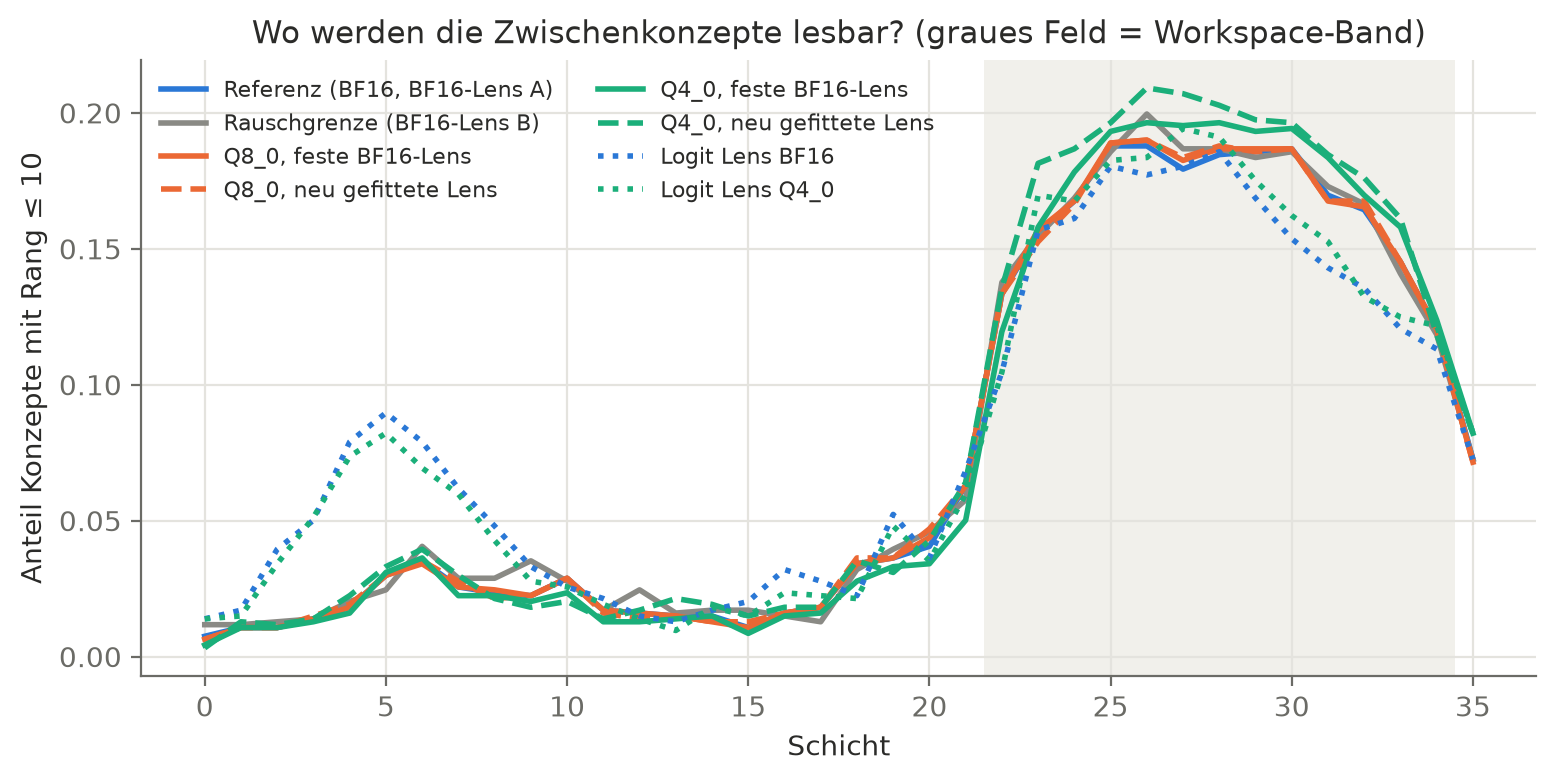

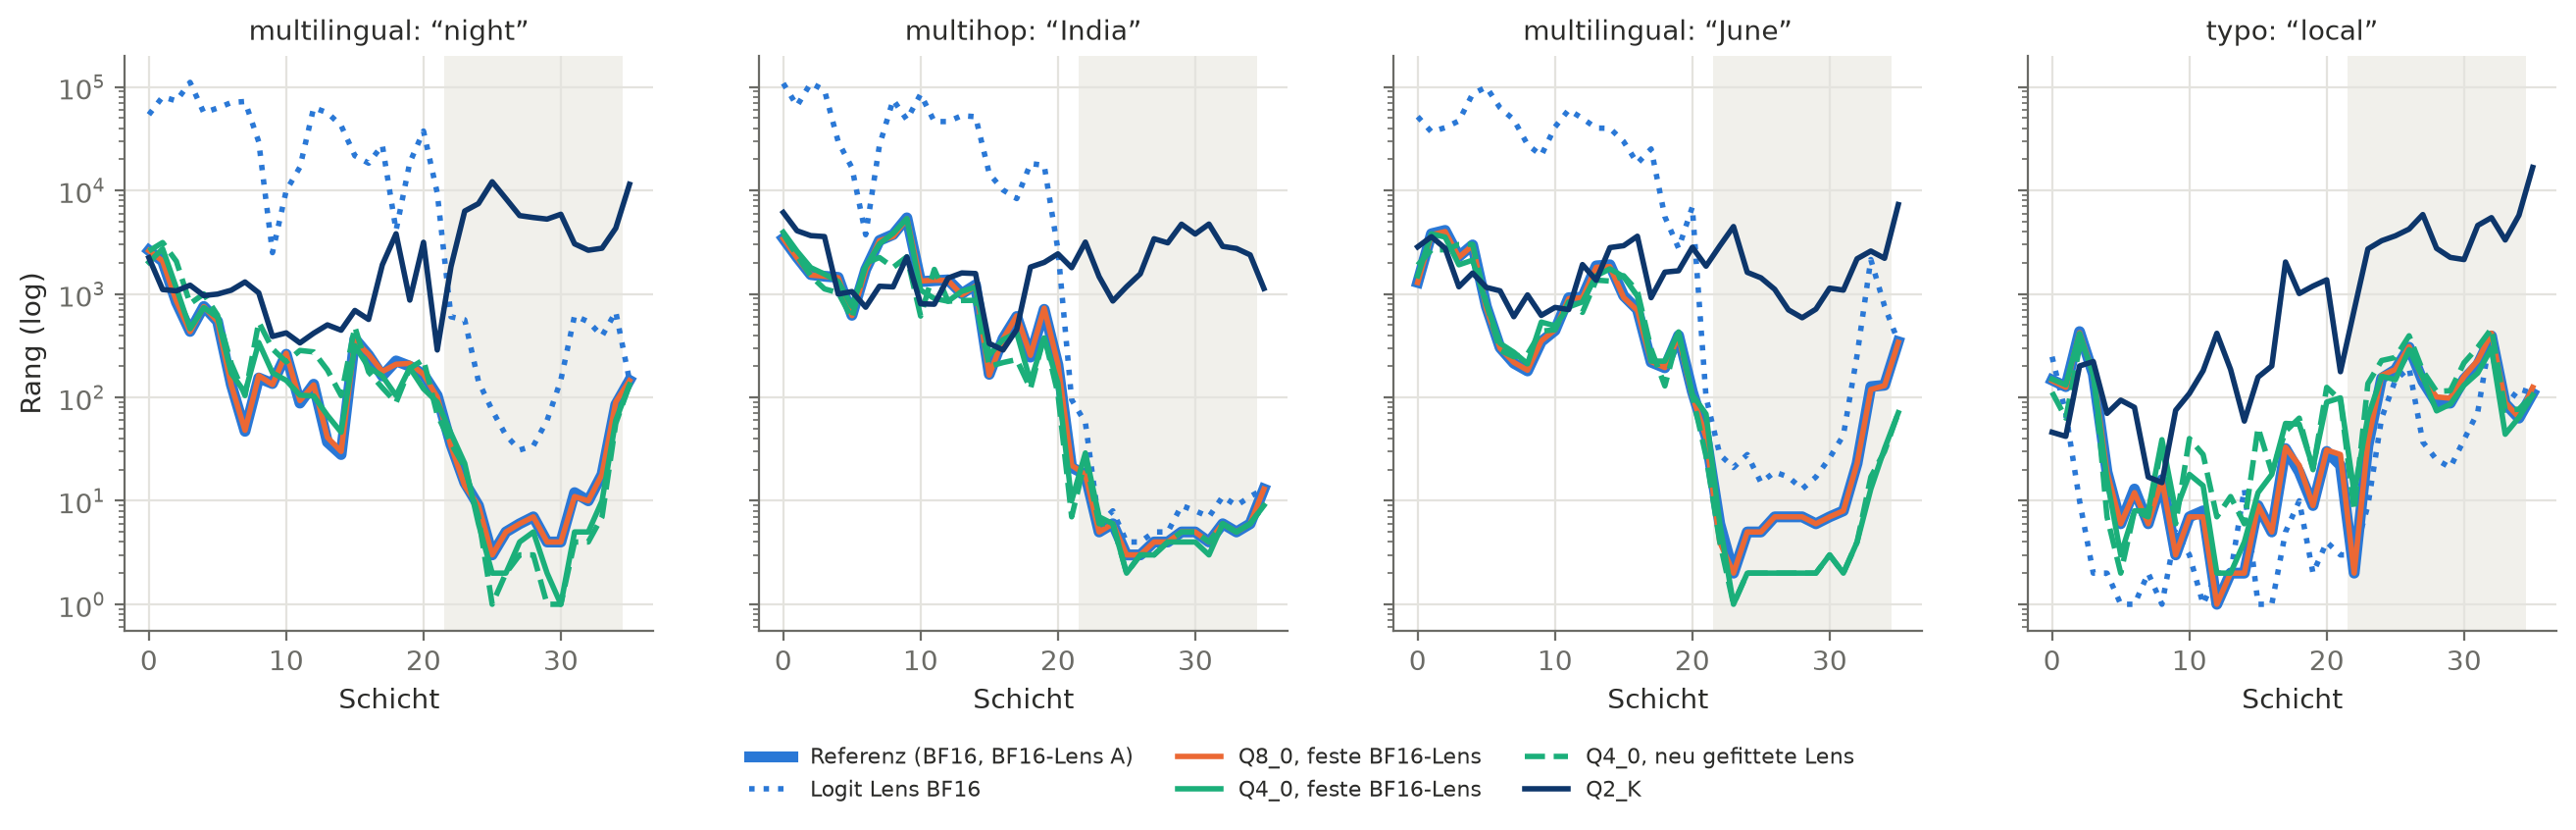

In [7]:
print("workspace band:", band, "| floor sets:", summary["floor_sets"])
display(Image(F / "hit_rate_per_layer.png", width=900))
display(Image(F / "concept_trajectories.png", width=1100))

## 6. Überleben die Konzepte? (pass@10, Kern)

In [8]:
pak = pd.read_csv(T / "pass_at_k.csv")
tab = pak[(pak.k == 10) & (pak.set == config.AGG_CORE) & (pak.scope == config.SCOPE_ALL) & (pak.role == "fixed")]
tab[["arm", "pass_at_k", "delta_ref", "delta_ci_lo", "delta_ci_hi"]].reset_index(drop=True)

,arm,pass_at_k,delta_ref,delta_ci_lo,delta_ci_hi
0,q8_0|bf16-A,0.439,0.005,-0.003,0.014
1,q4_0|bf16-A,0.416,-0.019,-0.047,0.009
2,q5_0|bf16-A,0.425,-0.009,-0.027,0.008
3,q6_k|bf16-A,0.434,0.000,-0.011,0.011
4,q5_k|bf16-A,0.412,-0.022,-0.038,-0.008
5,q4_k|bf16-A,0.439,0.005,-0.015,0.027
6,q3_k|bf16-A,0.380,-0.055,-0.089,-0.019
7,q2_k|bf16-A,0.177,-0.258,-0.306,-0.211
8,q4_0-attn|bf16-A,0.416,-0.019,-0.039,0.003
9,q4_0-ffn|bf16-A,0.425,-0.009,-0.031,0.012


## 7. Die Readout-Verteilung driftet viel früher

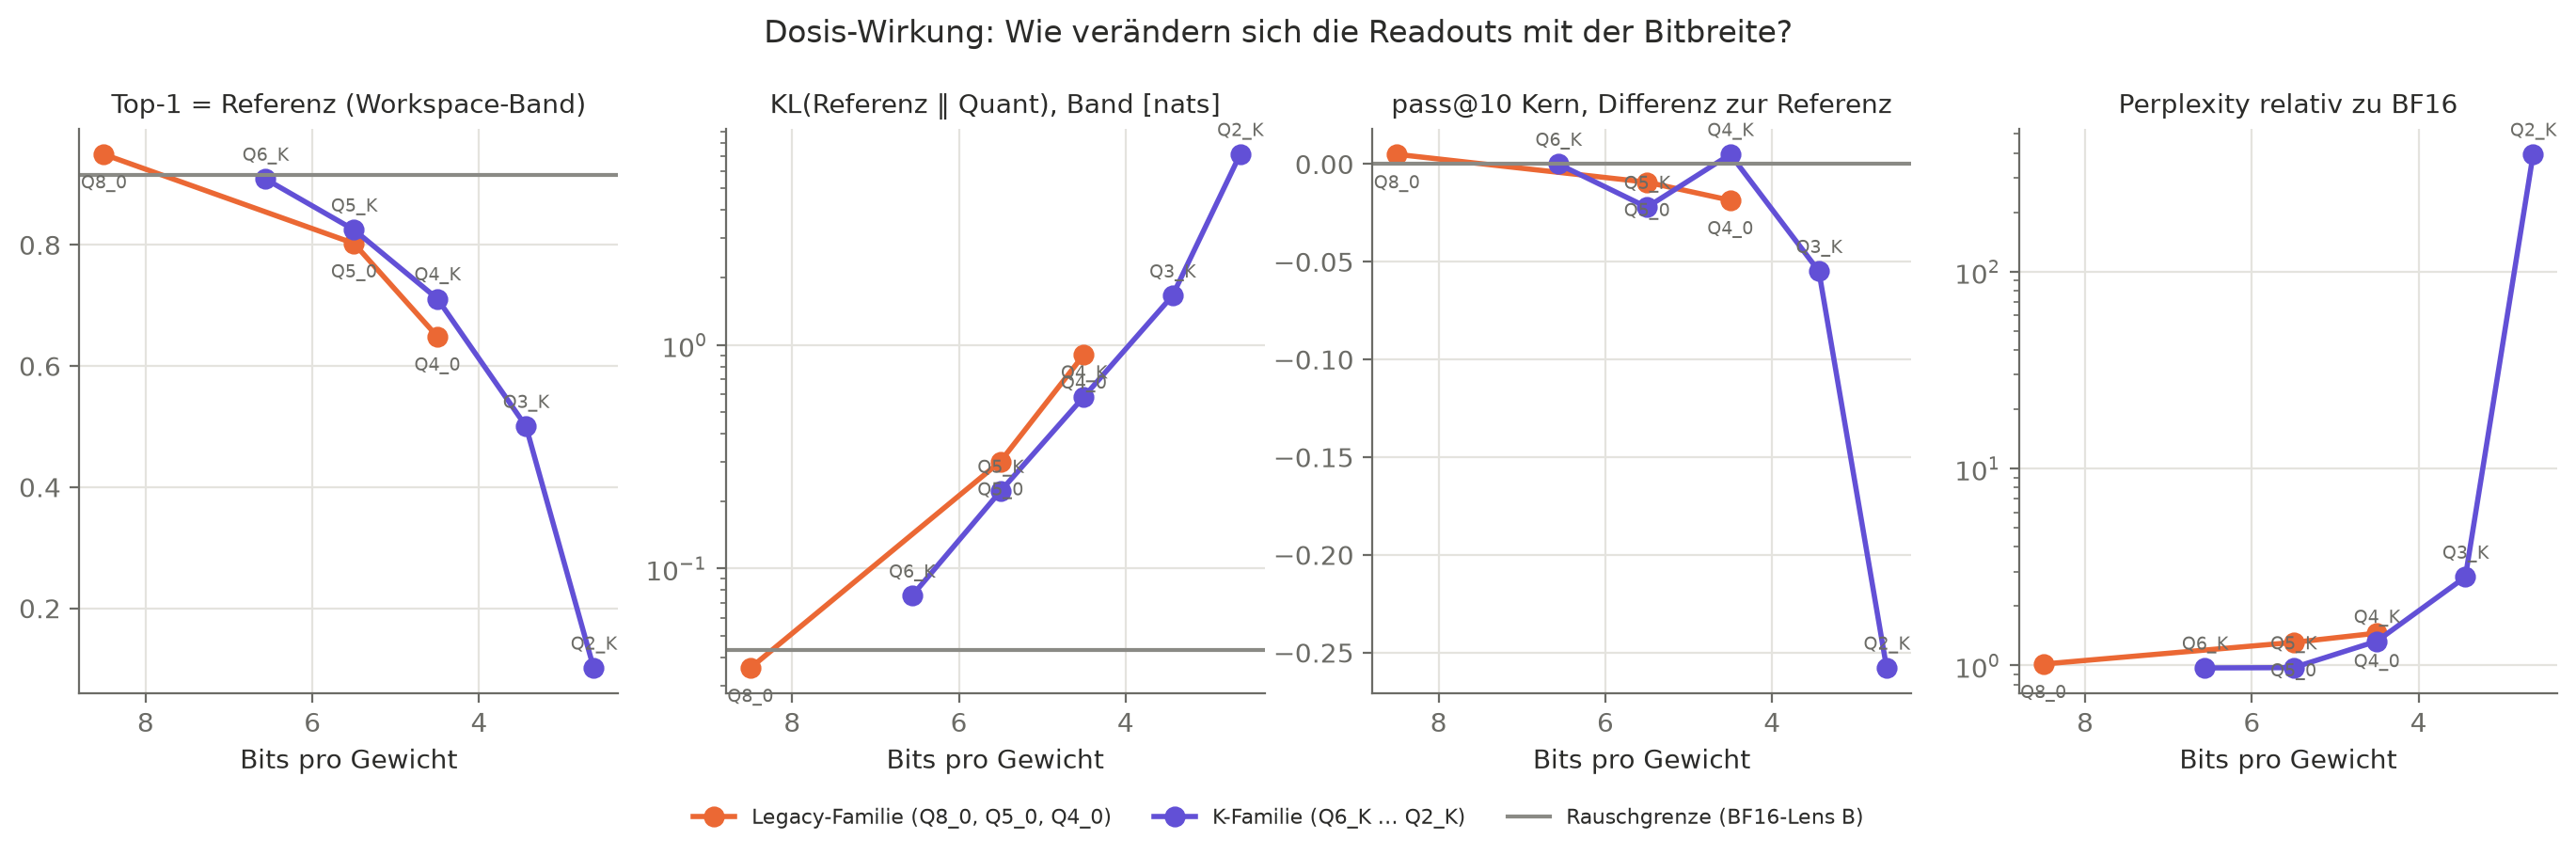

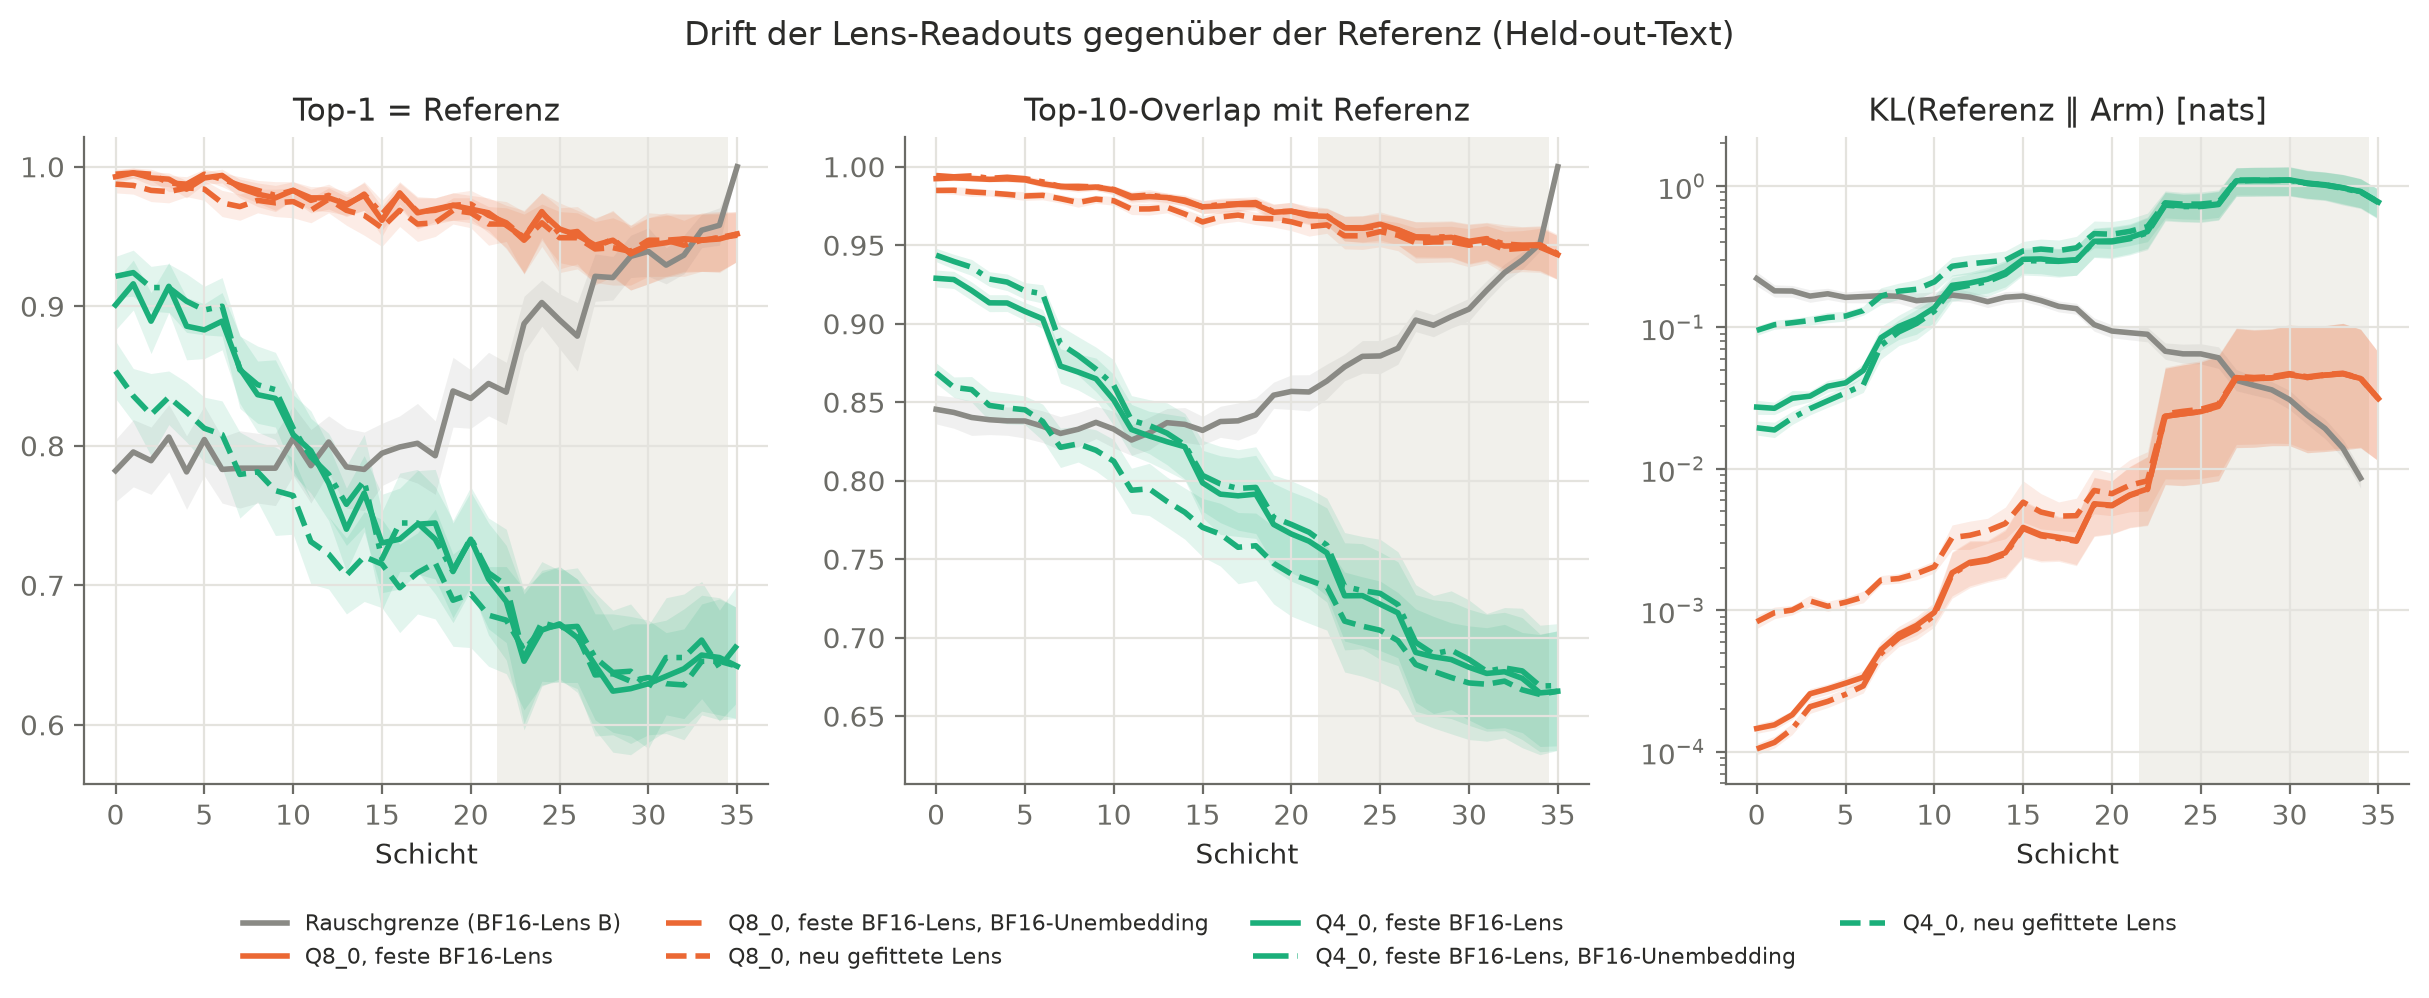

In [9]:
display(Image(F / "dose_response.png", width=1100))
display(Image(F / "agreement_per_layer_heldout.png", width=1100))

## 8. Repräsentationen ohne Lens, pro Schicht

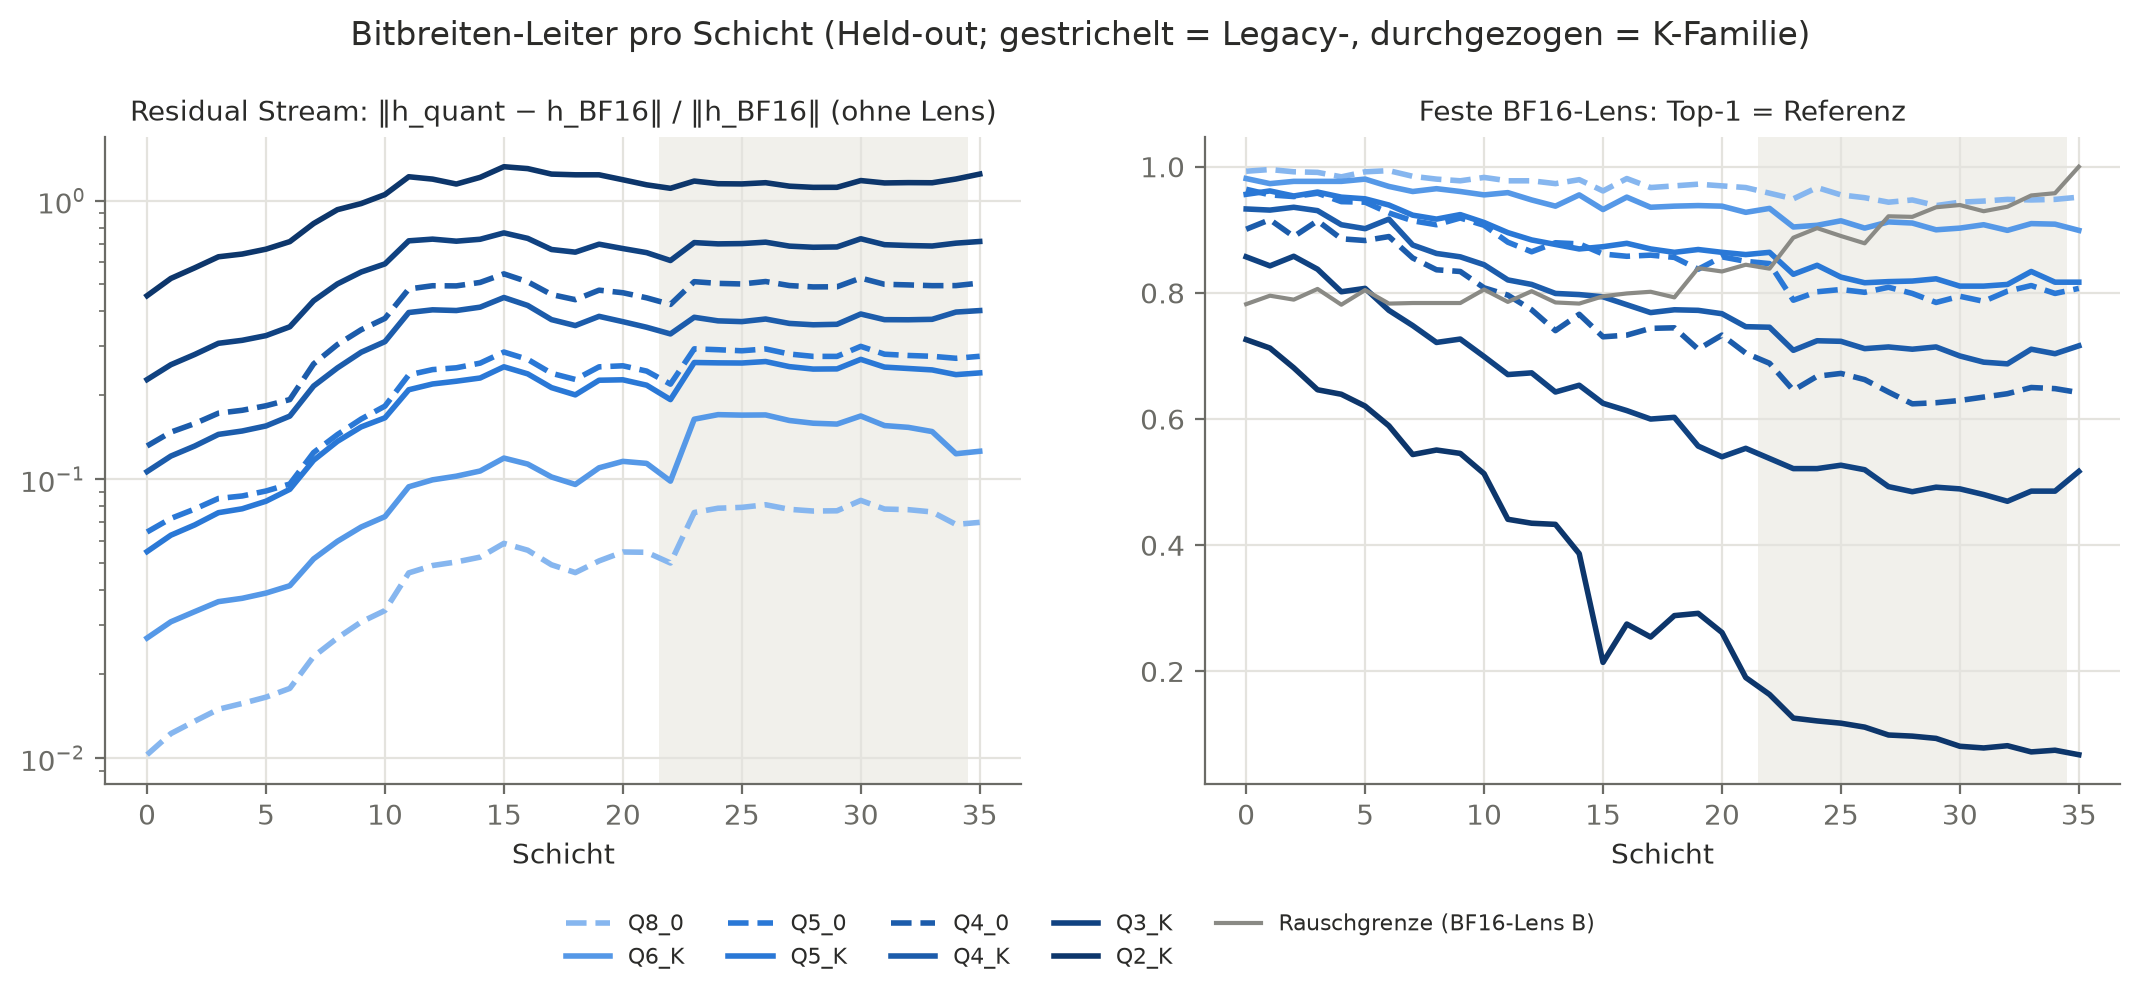

In [10]:
display(Image(F / "ladder_per_layer.png", width=1100))

## 9. Welche Komponente verursacht die Drift?

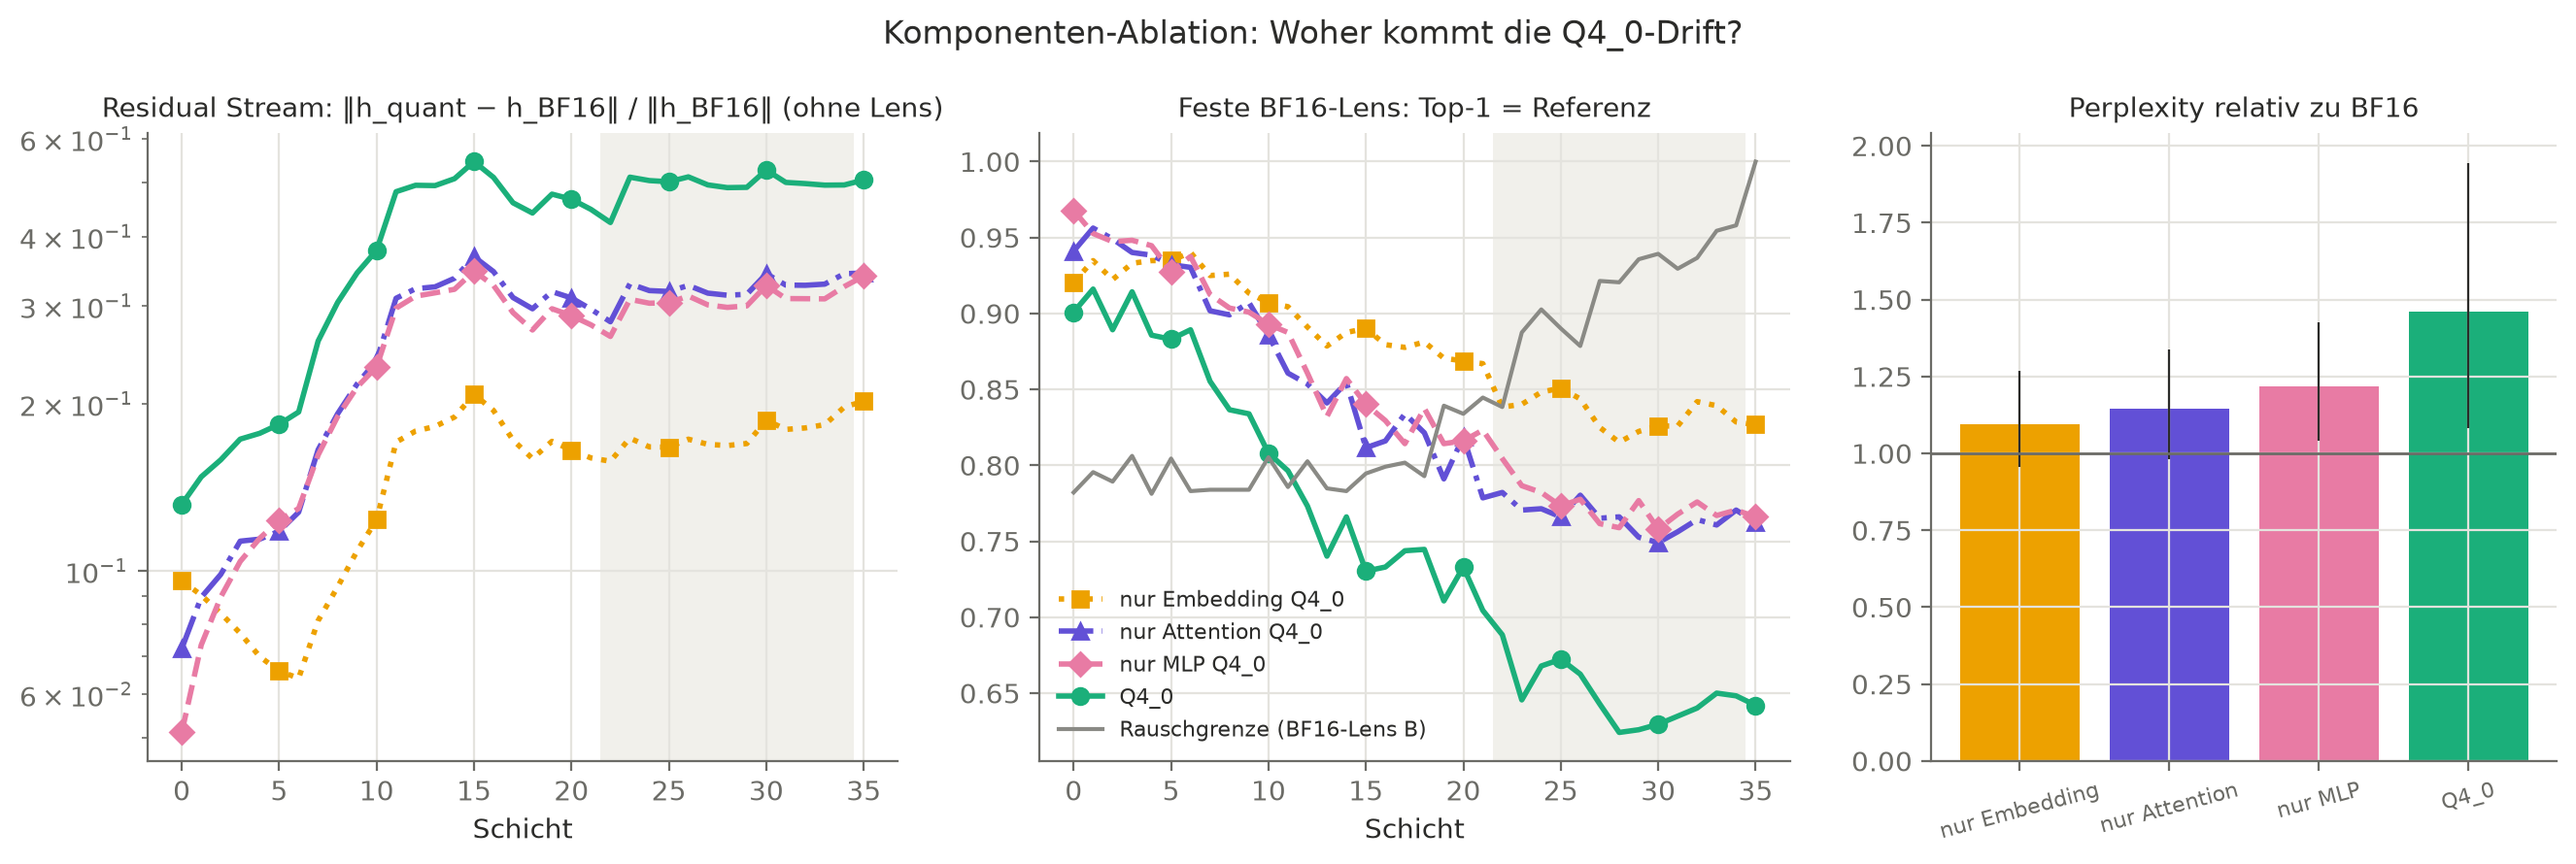

In [11]:
display(Image(F / "ablation.png", width=1100))

## 10. Welche Konzepte leiden?

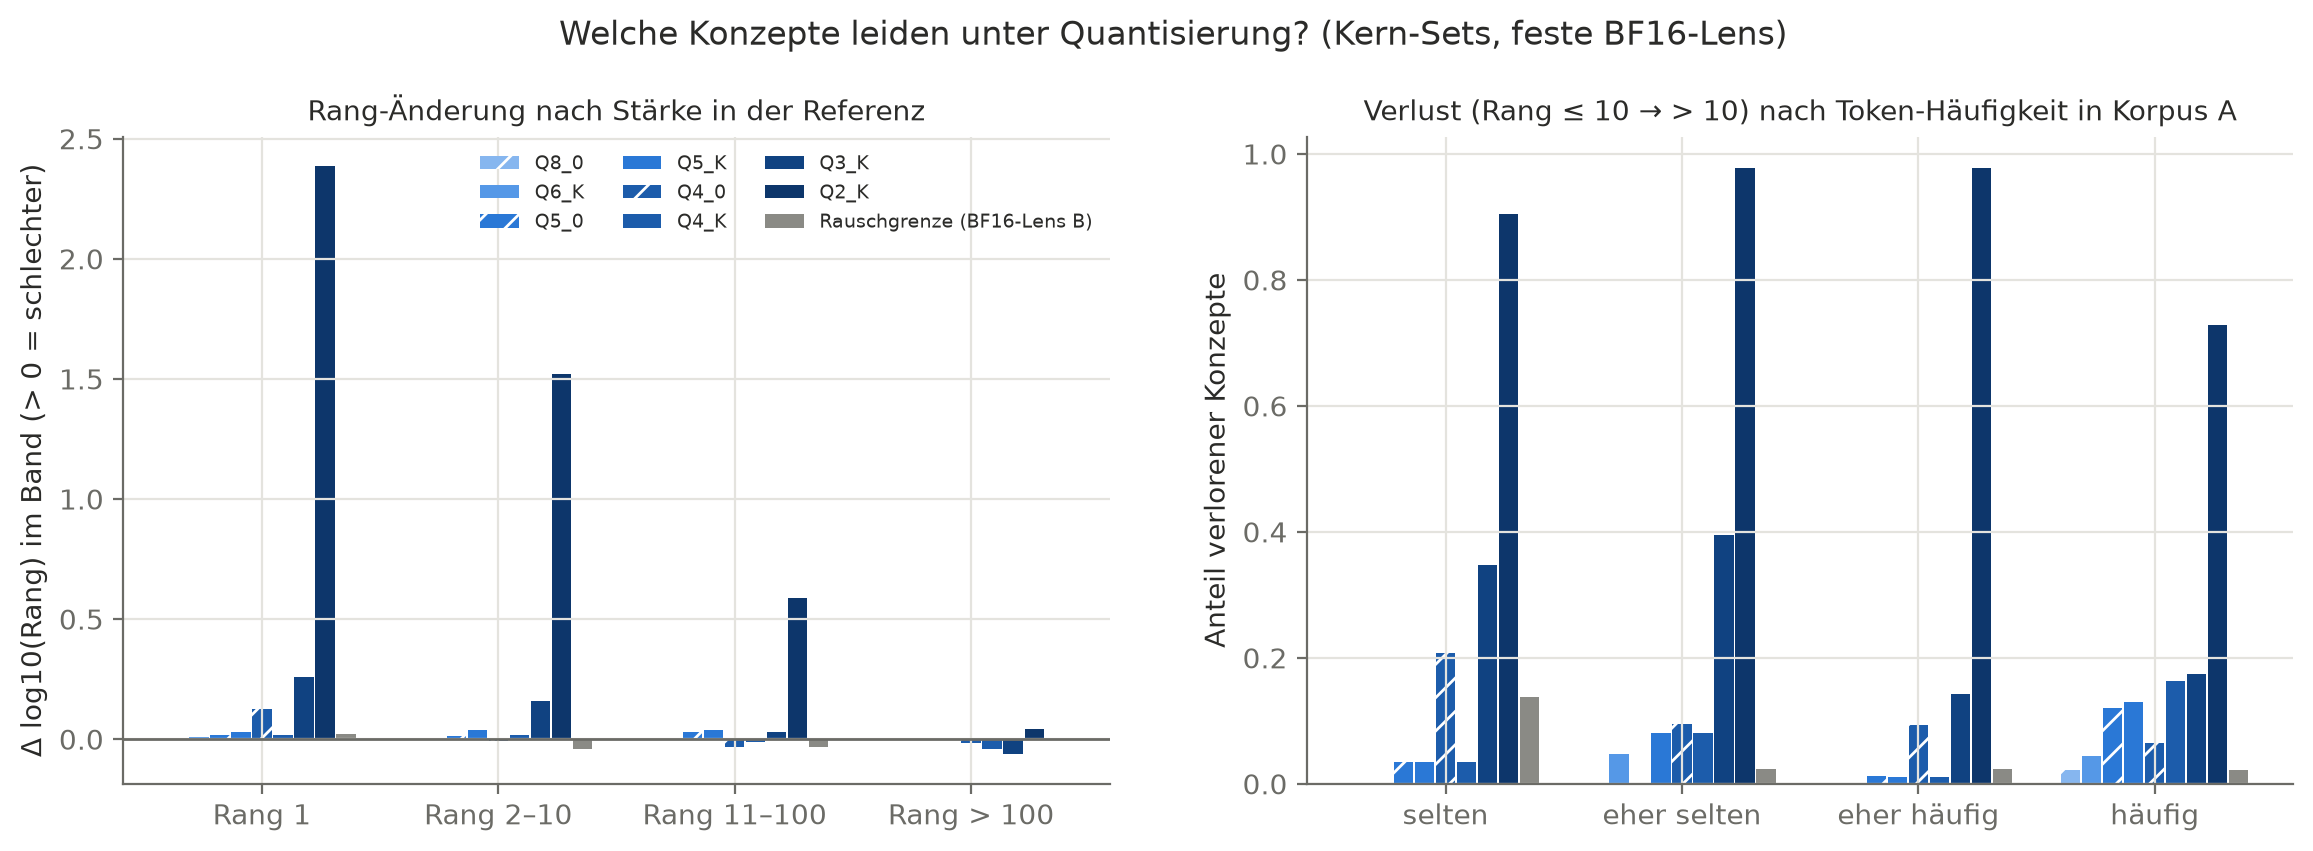

In [12]:
display(Image(F / "concept_loss.png", width=1100))

## 11. Kausaler Test: Steuern die Lens-Richtungen das Modell noch?

Auf dem Paper-Set `probe-swap` (z. B. „the language spoken in the country where the Amazon River ends
is“ → Brazil → Portuguese) lenken wir den Residual Stream in L18–L25 vom Brückenkonzept weg und zu einem
Tauschkonzept (Mexico) hin und prüfen, ob die Antwort folgt (Spanish).

,model,lens,baseline_accuracy,steer_success,steer_success_vs_ref,steer_success_vs_ref_ci_lo,steer_success_vs_ref_ci_hi,steer_control,ablate_drop
0,bf16,bf16-A,0.395,0.267,0.000,0.000,0.000,0.047,0.047
1,bf16,bf16-B,0.395,0.256,-0.012,-0.058,0.035,0.058,0.058
2,q2_k,bf16-A,0.012,0.012,-0.256,-0.349,-0.163,0.000,0.000
3,q3_k,bf16-A,0.221,0.151,-0.116,-0.198,-0.047,0.035,0.058
4,q4_0,bf16-A,0.384,0.233,-0.035,-0.116,0.035,0.058,0.047
5,q4_0,q4_0-A,0.384,0.209,-0.058,-0.140,0.012,0.070,0.058
6,q4_0-attn,bf16-A,0.407,0.256,-0.012,-0.070,0.035,0.058,0.070
7,q4_0-embd,bf16-A,0.395,0.256,-0.012,-0.047,0.023,0.047,0.035
8,q4_0-ffn,bf16-A,0.407,0.221,-0.047,-0.116,0.012,0.047,0.070
9,q4_k,bf16-A,0.384,0.244,-0.023,-0.081,0.035,0.035,0.047


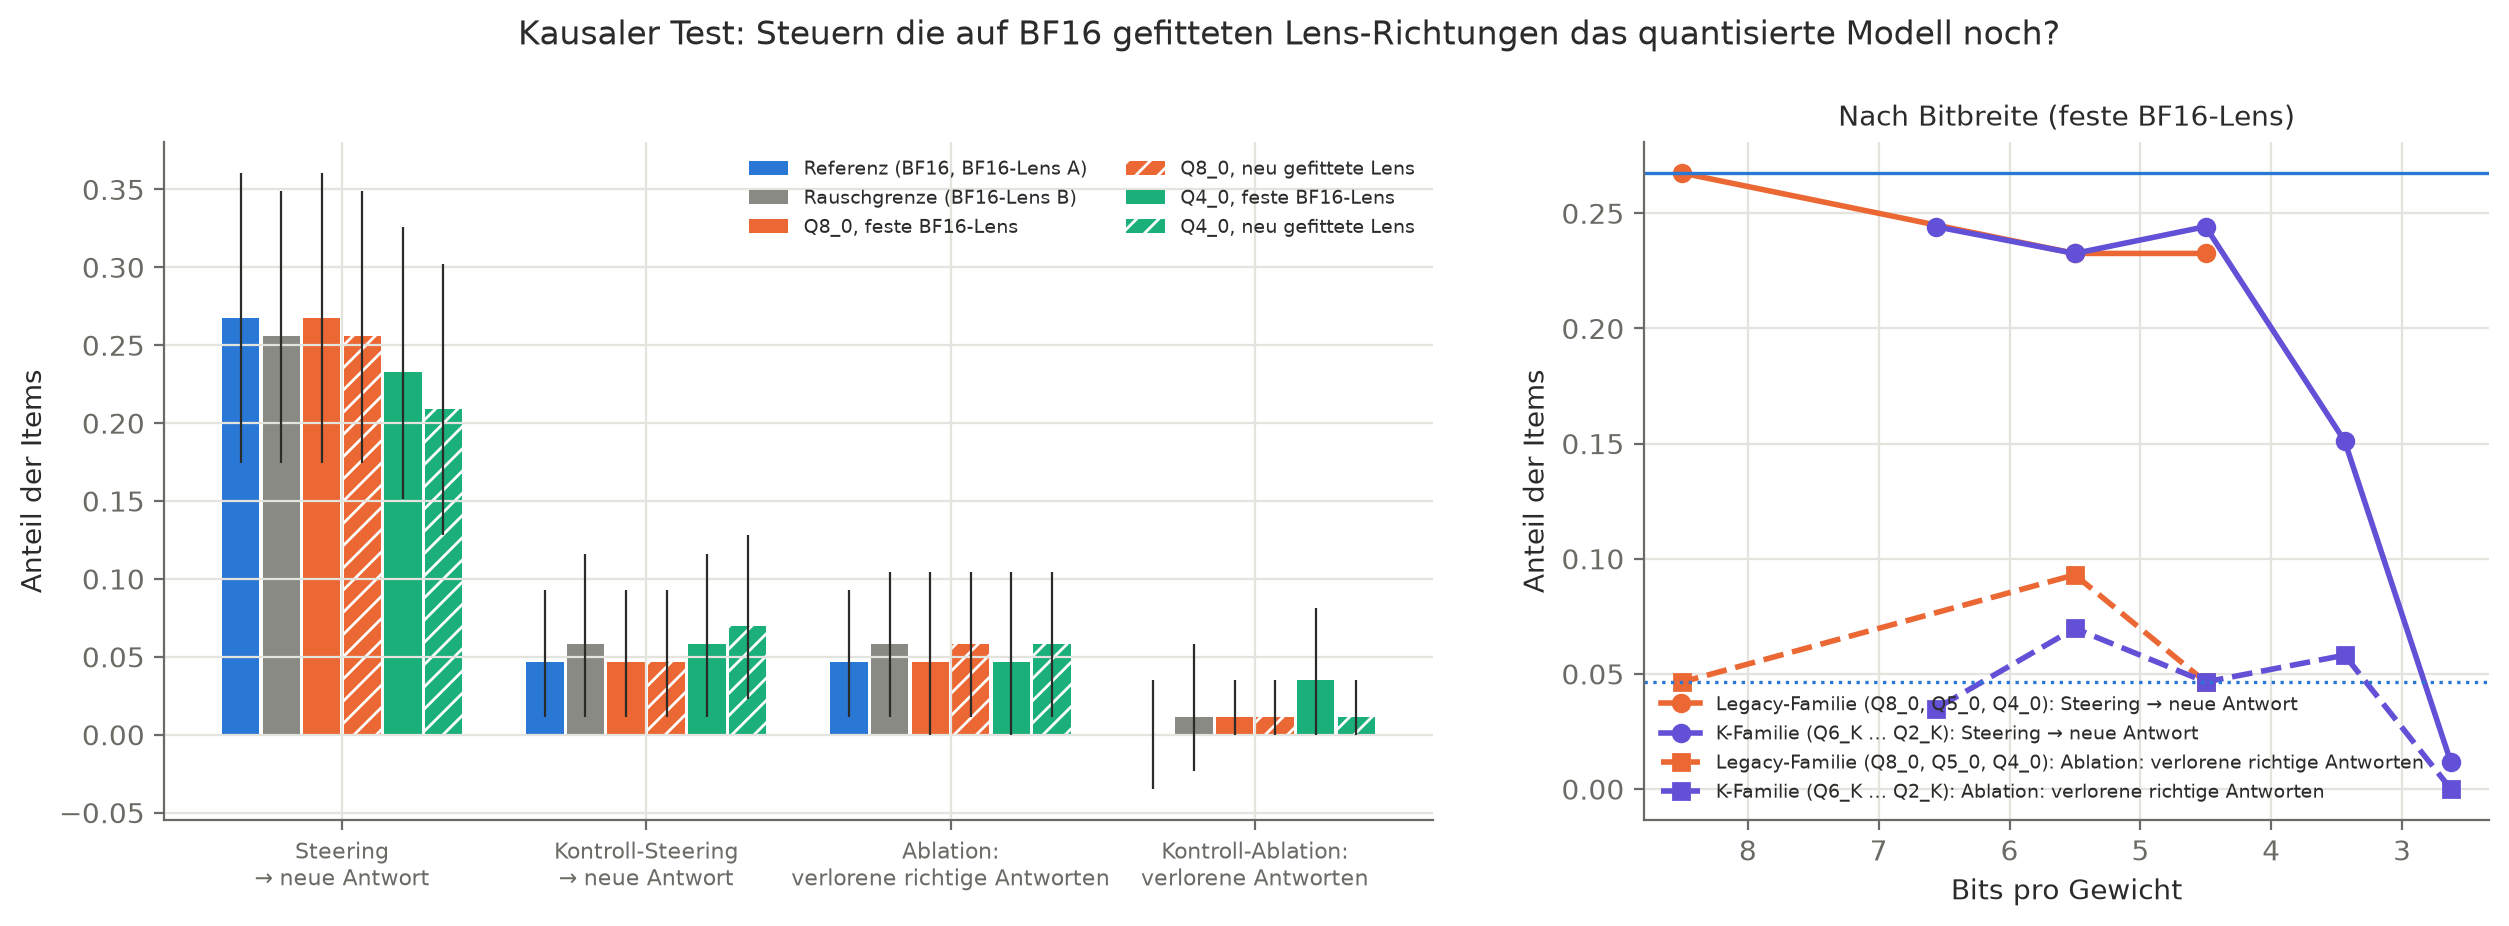

In [13]:
iv = pd.read_csv(T / "interventions_summary.csv")
display(iv[["model", "lens", "baseline_accuracy", "steer_success", "steer_success_vs_ref",
            "steer_success_vs_ref_ci_lo", "steer_success_vs_ref_ci_hi", "steer_control", "ablate_drop"]])
display(Image(F / "interventions.png", width=1100))

## 12. Verhaltenskontrolle

In [14]:
beh = pd.read_csv(T / "behavior.csv")
beh[beh.metric == "heldout_ppl"][["model", "value", "vs_ref", "vs_ref_ci_lo", "vs_ref_ci_hi"]].reset_index(drop=True)

,model,value,vs_ref,vs_ref_ci_lo,vs_ref_ci_hi
0,bf16,113.914,1.000,1.000,1.000
1,q8_0,115.839,1.017,0.976,1.072
2,q5_0,149.178,1.310,1.118,1.569
3,q4_0,166.264,1.460,1.081,1.944
4,q6_k,110.707,0.972,0.917,1.031
5,q5_k,111.120,0.975,0.870,1.095
6,q4_k,151.361,1.329,1.130,1.593
7,q3_k,320.650,2.815,2.154,3.686
8,q2_k,44816.952,393.427,194.250,771.558
9,q4_0-attn,130.452,1.145,0.982,1.339


## 13. Fazit

- **8 bit** ändert nichts Messbares.
- **Bis 4 bit** bleiben die verborgenen Konzepte lesbar, obwohl die Readout-Verteilung schon ab ~6 bit
  deutlich und mit der Tiefe wachsend driftet. Eine neu gefittete Lens holt Verluste zurück: Der Raum ist
  verschoben, nicht zerstört.
- **3 bit** kostet Konzepte, **2 bit** zerstört sie.
- Steering entlang der Lens-Richtungen wirkt bis 4 bit auch auf den quantisierten Modellen kausal.

Grenzen und Reflexion: `docs/de/05-ergebnisse.md`.